<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BLab%206%5D%20DSA211_06_Lab_Classification_Generative_Classifiers_sol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### DSA211 Statistical Learning
## Lab 6: Classification II — Generative Classifiers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay

## The Caravan Dataset

The **Caravan** dataset contains information on 5822 customers of a Dutch insurance company. The outcome variable `Purchase` records whether each customer purchased a caravan insurance policy. The remaining 85 variables describe sociodemographic and product ownership characteristics of the customers.

This is a challenging classification problem: only 6% of customers purchased insurance. We will use it to compare logistic regression, LDA, and Naive Bayes, and to see whether the dataset characteristics favour any particular classifier.

In [2]:
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Caravan.csv'
caravan = pd.read_csv(url)
caravan.index = range(1, len(caravan) + 1)

# Encode outcome: 1 = Yes, 0 = No
caravan['Purchase_bin'] = (caravan['Purchase'] == 'Yes').astype(int)

print(caravan.shape)
caravan.head()

(5822, 87)


,MOSTYPE,MAANTHUI,MGEMOMV,MGEMLEEF,MOSHOOFD,MGODRK,MGODPR,MGODOV,MGODGE,MRELGE,...,AGEZONG,AWAOREG,ABRAND,AZEILPL,APLEZIER,AFIETS,AINBOED,ABYSTAND,Purchase,Purchase_bin
1,33,1,3,2,8,0,5,1,3,7,...,0,0,1,0,0,0,0,0,No,0
2,37,1,2,2,8,1,4,1,4,6,...,0,0,1,0,0,0,0,0,No,0
3,37,1,2,2,8,0,4,2,4,3,...,0,0,1,0,0,0,0,0,No,0
4,9,1,3,3,3,2,3,2,4,5,...,0,0,1,0,0,0,0,0,No,0
5,40,1,4,2,10,1,4,1,4,7,...,0,0,1,0,0,0,0,0,No,0


## Part 0: EDA

In [3]:
# Outcome distribution
counts = caravan['Purchase'].value_counts()
print(counts)
print(f"\nBase rate (Purchase = Yes): {counts['Yes'] / len(caravan):.4f}")

Purchase
No     5474
Yes     348
Name: count, dtype: int64

Base rate (Purchase = Yes): 0.0598


In [4]:
# Summary statistics for the first five predictors by class
print("Mean for the first five predictors by class:")
caravan.groupby('Purchase')[caravan.columns[:5]].mean()

Mean for the first five predictors by class:


,MOSTYPE,MAANTHUI,MGEMOMV,MGEMLEEF,MOSHOOFD
Purchase,,,,,
No,24.478078,1.111619,2.671721,2.990318,5.823529
Yes,20.718391,1.094828,2.790230,3.005747,4.988506


In [5]:
# Distribution of predictor values: number of categories, and how often each is zero
predictors = caravan.drop(columns=['Purchase', 'Purchase_bin'])

n_unique = predictors.nunique()
print("Number of categories per predictor:")
print(n_unique.value_counts().sort_index())

zero_frac = (predictors == 0).mean()
bands = pd.cut(zero_frac, [-0.001, 0.1, 0.5, 0.8, 1.0],
               labels=['<10%', '10-50%', '50-80%', '>80%'])
print("\nPredictors by proportion of zero values:")
print(bands.value_counts().reindex(['<10%', '10-50%', '50-80%', '>80%']))
print(f"\nOverall proportion of zero entries: {(predictors == 0).values.mean():.3f}")

Number of categories per predictor:
2      5
3      9
4      8
5      8
6      8
7      6
8      4
9      3
10    33
40     1
Name: count, dtype: int64

Predictors by proportion of zero values:
<10%      18
10-50%    24
50-80%     6
>80%      37
Name: count, dtype: int64

Overall proportion of zero entries: 0.556


> *EDA note: two features of this dataset matter for what follows. First, the predictors are ordinal or near-binary, most taking fewer than 10 distinct values. This is a departure from the continuous Gaussian predictors assumed by LDA and Naive Bayes. Second, the dataset is sparse: over half of all entries are zero, and 37 of the 85 predictors are more than 80% zero. These are the product-ownership variables, which record how many policies of each type a customer holds. Keep both in mind when interpreting the classifier comparison.*

***

## Part 1: Naive Bayes

We begin with Naive Bayes. The lecture showed the full classification pipeline on a single predictor. Here we apply it to all 85 predictors and examine what the model learns.

In [6]:
# Prepare feature matrix and outcome vector
X = caravan.drop(columns=['Purchase', 'Purchase_bin']).values
y = caravan['Purchase_bin'].values
feature_names = caravan.drop(columns=['Purchase', 'Purchase_bin']).columns.tolist()



### 1.1 Fit and Inspect

In [7]:
# Fit Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X, y);

print(f"Class priors: No = {gnb.class_prior_[0]:.4f}, Yes = {gnb.class_prior_[1]:.4f}")

Class priors: No = 0.9402, Yes = 0.0598


In [8]:
# Class-conditional means for the first 10 predictors
means_df = pd.DataFrame(
    {'No': gnb.theta_[0, :10], 'Yes': gnb.theta_[1, :10]},
    index=feature_names[:10]
)
means_df['Difference'] = means_df['Yes'] - means_df['No']
means_df

,No,Yes,Difference
MOSTYPE,24.478078,20.718391,-3.759687
MAANTHUI,1.111619,1.094828,-0.016791
MGEMOMV,2.671721,2.790230,0.118509
MGEMLEEF,2.990318,3.005747,0.015429
MOSHOOFD,5.823529,4.988506,-0.835024
MGODRK,0.694921,0.721264,0.026343
MGODPR,4.612715,4.850575,0.237860
MGODOV,1.068871,1.086207,0.017336
MGODGE,3.275301,2.994253,-0.281049
MRELGE,6.149616,6.715517,0.565901


❓ **Question 1.1.** The `Difference` column shows the gap between class-conditional means for each predictor. What does a large positive difference tell you about the relationship between that predictor and the likelihood of purchasing insurance?

A large positive difference means the average value of that predictor is higher among customers who purchased insurance than among those who did not. It suggests the predictor is positively associated with purchase likelihood. Customers with higher values on that predictor are more likely to buy. In Naive Bayes terms, a higher value of that predictor shifts the posterior toward the Yes class.

### 1.2 Posterior Probabilities and the Default Threshold

In [9]:
# Posterior probabilities
probs_nb = gnb.predict_proba(X)
print("First 10 posterior probabilities:")
print(pd.DataFrame(probs_nb[:10], columns=['P(No)', 'P(Yes)']))

First 10 posterior probabilities:
          P(No)        P(Yes)
0  1.917090e-08  1.000000e+00
1  1.287379e-08  1.000000e+00
2  2.933325e-07  9.999997e-01
3  3.356488e-09  1.000000e+00
4  8.156212e-08  9.999999e-01
5  1.022979e-01  8.977021e-01
6  9.156628e-06  9.999908e-01
7  9.999999e-01  8.574661e-08
8  3.778011e-04  9.996222e-01
9  1.646181e-07  9.999998e-01


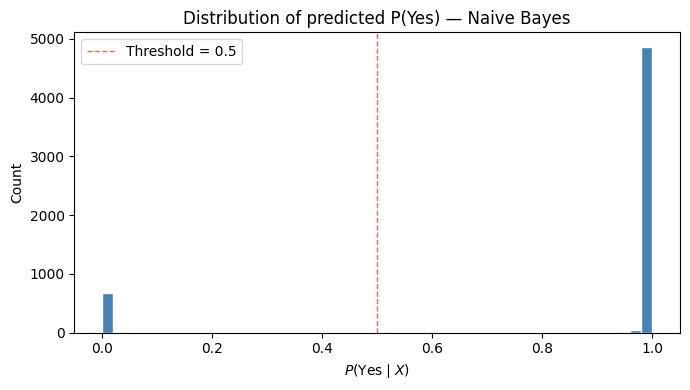

In [10]:
# Distribution of predicted P(Yes)
plt.figure(figsize=(7, 4))
plt.hist(probs_nb[:, 1], bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.5, color='tomato', linestyle='--', linewidth=1, label='Threshold = 0.5')
plt.xlabel(r'$P(\mathrm{Yes} \mid X)$')
plt.ylabel('Count')
plt.title('Distribution of predicted P(Yes) — Naive Bayes')
plt.legend()
plt.tight_layout()
plt.show()

❓ **Question 1.2.** Look at the histogram. The predicted probabilities are concentrated near 0 and near 1, with almost nothing in between. This is a known consequence of the conditional independence assumption with many predictors. The product of marginal likelihoods pushes posteriors toward the extremes. What does the spike near 1.0 tell you about how many customers Naive Bayes predicts as `Yes` at the default threshold? Given the 6% base rate, does the size of that spike seem reasonable?

The spike near 1.0 means Naive Bayes predicts a substantial number of customers as `Yes`, far more than the 6% base rate would suggest. With 85 predictors and the independence assumption, the product of 85 marginal likelihoods amplifies small differences between classes and pushes posteriors to the extremes. The predicted probabilities are not trustworthy as probability estimates, even if the rankings and therefore AUC, can still be reasonable.

### 1.3 Confusion Matrix at Default Threshold

In [11]:
# A confusion matrix and the four rates, at any threshold.
# Used throughout this lab, so it is written once here.
def report(y_true, y_prob, threshold=0.5, label=''):
    y_hat = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    print(f"{label}  (threshold = {threshold})")
    print(pd.DataFrame([[tn, fp], [fn, tp]],
                       index=['Actual No', 'Actual Yes'],
                       columns=['Predicted No', 'Predicted Yes']))
    print(f"  Sensitivity {tp / (tp + fn):.4f}    Specificity {tn / (tn + fp):.4f}"
          f"    Precision {tp / (tp + fp):.4f}    Accuracy {(tp + tn) / len(y_true):.4f}\n")

report(y, probs_nb[:, 1], 0.5, 'Gaussian Naive Bayes')

Gaussian Naive Bayes  (threshold = 0.5)
            Predicted No  Predicted Yes
Actual No            758           4716
Actual Yes            14            334
  Sensitivity 0.9598    Specificity 0.1385    Precision 0.0661    Accuracy 0.1876



❓ **Question 1.3.** The confusion matrix shows that Naive Bayes predicts almost every customer as `Yes`. This is consistent with the bimodal posteriors in Question 1.2. If an insurance company used this classifier to target customers for a marketing campaign, what would the practical consequence be?

Nearly every customer gets targeted. The true purchasers are identified (high sensitivity), but the company wastes resources contacting roughly 4700 non-buyers for every 334 genuine buyers it finds. The precision is very low since of all customers predicted as `Yes`, only about 6% actually buy. In a direct marketing context where contact has a cost, this is essentially equivalent to no classifier at all.

### 1.4 Lowering the Threshold

The default threshold of 0.5 is inappropriate when the base rate is 6%. A more useful operating point is one that sacrifices some specificity to recover more true positives.

### Exercise 1.4: Naive Bayes at a lower threshold

In [12]:
### YOUR CODE HERE
# Apply a threshold of 0.20 to the Naive Bayes posterior probabilities
# Report the confusion matrix and rates with report()
# Compare to the default threshold results above

report(y, probs_nb[:, 1], 0.20, 'Gaussian Naive Bayes')

Gaussian Naive Bayes  (threshold = 0.2)
            Predicted No  Predicted Yes
Actual No            728           4746
Actual Yes            12            336
  Sensitivity 0.9655    Specificity 0.1330    Precision 0.0661    Accuracy 0.1828



❓ **Question 1.4.** Does performance change meaningfully? Explain why threshold selection has little effect here, and what property of the posterior distribution is responsible.

Performance barely changes because almost no observations have predicted probabilities between 0.20 and 0.50. The bimodal posteriors mean crossing the threshold moves very few observations from one class to the other. Threshold selection is only effective when the posterior is spread across the probability range, giving you observations to move across the boundary as you adjust it. Here the miscalibration from the independence assumption with 85 predictors has already pushed nearly all posteriors to the extremes, leaving the threshold with nothing to work with.

### 1.5 The Bernoulli Variant

Gaussian Naive Bayes models each predictor as $X_j \mid Y = k \sim \mathcal{N}(\mu_{jk}, \sigma_{jk}^2)$. The EDA showed that assumption is wrong here: the predictors are small integers, and over half the entries are zero.

**Bernoulli Naive Bayes** makes a different assumption. Each predictor is treated as a binary indicator, and the class-conditional density is $P(X_j = 1 \mid Y = k) = p_{jk}$, estimated by the within-class proportion. The independence assumption is unchanged. Only the marginal density changes.

Binarising throws away the counts and keeps only "owns at least one". That discards information, so it is not obviously an improvement.

In [13]:
# Binarise: 1 if the customer has any of that product / falls in that band, 0 otherwise
X_bin = (X > 0).astype(int)
print(f"Shape: {X_bin.shape}, proportion of ones: {X_bin.mean():.3f}")

Shape: (5822, 85), proportion of ones: 0.444


### Exercise 1.5: Bernoulli Naive Bayes on binarised predictors

Bernoulli Naive Bayes  (threshold = 0.5)
            Predicted No  Predicted Yes
Actual No           5095            379
Actual Yes           245            103
  Sensitivity 0.2960    Specificity 0.9308    Precision 0.2137    Accuracy 0.8928

AUC — Bernoulli Naive Bayes: 0.7419
AUC — Gaussian  Naive Bayes: 0.7300


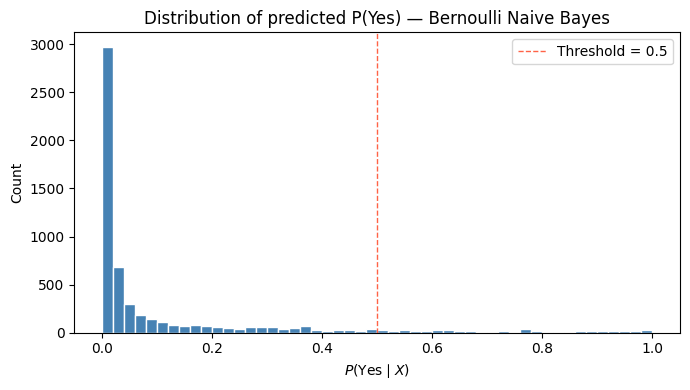

In [14]:
### YOUR CODE HERE
# Fit BernoulliNB on X_bin and y
# Report the confusion matrix and rates at the default threshold with report()
# Print the AUC, and compare it to the Gaussian Naive Bayes AUC
# Plot a histogram of the predicted P(Yes), as in section 1.2

bnb = BernoulliNB()
bnb.fit(X_bin, y)
probs_bnb = bnb.predict_proba(X_bin)

report(y, probs_bnb[:, 1], 0.5, 'Bernoulli Naive Bayes')
print(f"AUC — Bernoulli Naive Bayes: {roc_auc_score(y, probs_bnb[:, 1]):.4f}")
print(f"AUC — Gaussian  Naive Bayes: {roc_auc_score(y, probs_nb[:, 1]):.4f}")

plt.figure(figsize=(7, 4))
plt.hist(probs_bnb[:, 1], bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.5, color='tomato', linestyle='--', linewidth=1, label='Threshold = 0.5')
plt.xlabel(r'$P(\mathrm{Yes} \mid X)$')
plt.ylabel('Count')
plt.title('Distribution of predicted P(Yes) — Bernoulli Naive Bayes')
plt.legend()
plt.tight_layout()
plt.show()

❓ **Question 1.5.** Bernoulli Naive Bayes discards the counts, yet it does not do worse. Compare its AUC and its posterior histogram against the Gaussian version in sections 1.2 and 1.3. Which assumption was doing the damage: conditional independence, or the Gaussian marginal?

Bernoulli Naive Bayes has the higher AUC (0.74 against 0.73), despite using strictly less information. Its posteriors are also far better behaved: roughly 11% of observations fall between 0.2 and 0.5, against under 1% for the Gaussian version, and only 0.3% are pushed above 0.99 where the Gaussian version puts 83%.

Both models make the same conditional independence assumption, so independence cannot be what separates them. The difference is the marginal density. Fitting a Gaussian to a predictor that is zero 90% of the time produces a tiny within-class variance, and the resulting likelihood ratios are extreme. Multiplying 85 of them drives the posterior to 0 or 1. The Bernoulli marginal matches the shape of the data, so the likelihood ratios stay moderate.

The lesson is that the independence assumption gets the blame for miscalibrated Naive Bayes posteriors more often than it deserves. Here a misspecified *marginal* was the larger problem. Note that the ranking is barely affected either way, which is why both AUCs sit near 0.73 while the accuracies differ by 70 percentage points.

***

## Part 2: LDA

We now fit LDA on the same dataset. Recall from the lecture that LDA differs from Naive Bayes in two ways: it uses a full (non-diagonal) pooled covariance matrix, and it pools that covariance across classes.

### 2.1 Fit and Inspect

### Exercise 2.1: Fit LDA

In [15]:
### YOUR CODE HERE
# Fit LDA on X and y
# Print the class priors
# Print the class means for the first 10 predictors

lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

print(f"Class priors: No = {lda.priors_[0]:.4f}, Yes = {lda.priors_[1]:.4f}")

print("\nClass means (first 10 predictors):")
means_lda = pd.DataFrame(
    {'No': lda.means_[0, :10], 'Yes': lda.means_[1, :10]},
    index=feature_names[:10]
)
means_lda['Difference'] = means_lda['Yes'] - means_lda['No']
print(means_lda)

Class priors: No = 0.9402, Yes = 0.0598

Class means (first 10 predictors):
                 No        Yes  Difference
MOSTYPE   24.478078  20.718391   -3.759687
MAANTHUI   1.111619   1.094828   -0.016791
MGEMOMV    2.671721   2.790230    0.118509
MGEMLEEF   2.990318   3.005747    0.015429
MOSHOOFD   5.823529   4.988506   -0.835024
MGODRK     0.694921   0.721264    0.026343
MGODPR     4.612715   4.850575    0.237860
MGODOV     1.068871   1.086207    0.017336
MGODGE     3.275301   2.994253   -0.281049
MRELGE     6.149616   6.715517    0.565901


### 2.2 Confusion Matrix at Default Threshold

### Exercise 2.2: LDA at the default threshold

In [16]:
### YOUR CODE HERE
# Predict using LDA at the default threshold
# Report the confusion matrix and rates with report()

probs_lda = lda.predict_proba(X)
report(y, probs_lda[:, 1], 0.5, 'LDA')

LDA  (threshold = 0.5)
            Predicted No  Predicted Yes
Actual No           5435             39
Actual Yes           326             22
  Sensitivity 0.0632    Specificity 0.9929    Precision 0.3607    Accuracy 0.9373



❓ **Question 2.2.** LDA produces a very different confusion matrix from Naive Bayes. Compare this to the Naive Bayes results. Which metric drives the high accuracy here, and why is it misleading? Between LDA and Naive Bayes at the default threshold, which would be more useful to an insurance company running a targeted marketing campaign, and why?

LDA's high accuracy (0.94) is driven entirely by specificity. It predicts almost everyone as No, which is correct 94% of the time (base rate). Sensitivity is only 0.06, meaning LDA identifies almost none of the actual purchasers. Precision is higher than Naive Bayes (0.36 vs 0.07) because the few customers LDA does flag as Yes are more likely to be genuine buyers but it flags so few that the campaign would miss almost all of them.

For a targeted marketing campaign, Naive Bayes is more useful despite its poor accuracy. It recovers nearly all true purchasers (sensitivity 0.96) at the cost of also targeting most non-buyers. Whether that trade-off is acceptable depends on the cost of contacting a non-buyer.

### 2.3 Lowering the Threshold

### Exercise 2.3: LDA at a lower threshold

In [17]:
### YOUR CODE HERE
# Apply a threshold of 0.20 to the LDA posterior probabilities
# Report the confusion matrix and rates with report()
# Try changing the threshold — add a comment indicating what you tried

threshold = [0.20, 0.10, 0.05]
for i in threshold:
  report(y, probs_lda[:, 1], i, 'LDA')


#report(y, probs_lda[:, 1], 0.20, 'LDA')

# Thresholds to try: 0.20, 0.10, 0.05

LDA  (threshold = 0.2)
            Predicted No  Predicted Yes
Actual No           5280            194
Actual Yes           263             85
  Sensitivity 0.2443    Specificity 0.9646    Precision 0.3047    Accuracy 0.9215

LDA  (threshold = 0.1)
            Predicted No  Predicted Yes
Actual No           4790            684
Actual Yes           182            166
  Sensitivity 0.4770    Specificity 0.8750    Precision 0.1953    Accuracy 0.8513

LDA  (threshold = 0.05)
            Predicted No  Predicted Yes
Actual No           3844           1630
Actual Yes            97            251
  Sensitivity 0.7213    Specificity 0.7022    Precision 0.1334    Accuracy 0.7034



❓ **Question 2.3.** Compare the effect of lowering the threshold here with the effect it had on Naive Bayes in Question 1.4. Why does the same change to the threshold move LDA's confusion matrix but not Naive Bayes'?

Lowering the threshold from 0.5 to 0.2 meaningfully improves LDA's sensitivity, from 0.06 to 0.24. LDA now identifies four times as many true purchasers, at the cost of flagging more non-buyers.

The same change did almost nothing to Naive Bayes, because its posteriors are bimodal and there are almost no observations between 0.2 and 0.5 to move. LDA's posteriors are not pushed to the extremes in the same way, so there are observations in that range for the threshold to reclassify. A threshold is only a useful control when the posterior is spread across the probability range. That is a property of the fitted model, not of the threshold.

***

## Part 3: Within-Class Correlation Structure

The lecture showed that LDA and Naive Bayes behave similarly when within-class correlations are small. Here we check whether that holds for the Caravan data. Pearson correlation is not appropriate for ordinal/categorical data. We use Spearman rank correlation instead.

In [18]:
# Within-class Spearman correlation matrices for the first 10 predictors
for label in ['No', 'Yes']:
    subset = caravan[caravan['Purchase'] == label][feature_names[:10]]
    print(f"\nClass {label} — Spearman correlation (first 10 predictors):")
    print(subset.corr(method='spearman').round(2))


Class No — Spearman correlation (first 10 predictors):
          MOSTYPE  MAANTHUI  MGEMOMV  MGEMLEEF  MOSHOOFD  MGODRK  MGODPR  \
MOSTYPE      1.00     -0.05     0.06     -0.00      0.99   -0.19    0.10   
MAANTHUI    -0.05      1.00     0.03     -0.01     -0.04   -0.04   -0.01   
MGEMOMV      0.06      0.03     1.00     -0.33      0.07    0.02    0.05   
MGEMLEEF    -0.00     -0.01    -0.33      1.00     -0.01   -0.02    0.09   
MOSHOOFD     0.99     -0.04     0.07     -0.01      1.00   -0.21    0.11   
MGODRK      -0.19     -0.04     0.02     -0.02     -0.21    1.00   -0.33   
MGODPR       0.10     -0.01     0.05      0.09      0.11   -0.33    1.00   
MGODOV      -0.05     -0.02    -0.12      0.03     -0.05    0.12   -0.29   
MGODGE      -0.04      0.01     0.02     -0.13     -0.03   -0.01   -0.74   
MRELGE      -0.01      0.03     0.52     -0.05      0.01   -0.06    0.14   

          MGODOV  MGODGE  MRELGE  
MOSTYPE    -0.05   -0.04   -0.01  
MAANTHUI   -0.02    0.01    0.03  
MG

❓ **Question 3.1.** The Spearman correlation matrices reveal two things. First, some predictor pairs are strongly correlated within both classes (e.g., MOSTYPE–MOSHOOFD, MGODPR–MGODGE). Second, the correlation structure is similar across the two classes. Based on these observations, which model, LDA or Naive Bayes, would you expect to handle the strong correlations better, and why? Does the similarity of correlations across classes support or undermine LDA's pooled covariance assumption?

The strong within-class correlations violate Naive Bayes' independence assumption. LDA handles this better because its covariance matrix captures these correlations explicitly.

The similarity of the correlation structure across the two classes supports LDA's pooled covariance assumption. Pooling is reasonable when the within-class covariance matrices are approximately equal. If they differed substantially, QDA would be more appropriate.

However, both models assume Gaussian class-conditional distributions, which is violated here since the predictors are ordinal. Hence, neither model is fully appropriate for this data type.

***

## Part 4: Classifier Comparison

We now fit all four classifiers — logistic regression, LDA, Gaussian Naive Bayes and Bernoulli Naive Bayes — and compare their performance using AUC and ROC curves.

### 4.1 Fit All Classifiers

In [19]:
# Define classifiers
clf_lr   = LogisticRegression(max_iter=1000, random_state=0)
clf_lda  = LinearDiscriminantAnalysis()
clf_gnb  = GaussianNB()
clf_bnb  = BernoulliNB()

In [20]:
# Fit classifiers. Bernoulli Naive Bayes takes the binarised predictors.
clf_lr.fit(X, y)
clf_lda.fit(X, y)
clf_gnb.fit(X, y)
clf_bnb.fit(X_bin, y);

### 4.2 Performance Summary

In [21]:
classifiers = {
    'Logistic':    (clf_lr,  X),
    'LDA':         (clf_lda, X),
    'GaussianNB':  (clf_gnb, X),
    'BernoulliNB': (clf_bnb, X_bin),
}

print(f"{'Classifier':<14}{'Accuracy':>10}{'AUC':>9}{'Sensitivity':>13}{'Specificity':>13}")
print('-' * 59)

for name, (clf, X_use) in classifiers.items():
    y_pred = clf.predict(X_use)
    y_prob = clf.predict_proba(X_use)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    print(f"{name:<14}{(y_pred == y).mean():>10.4f}{roc_auc_score(y, y_prob):>9.4f}"
          f"{tp / (tp + fn):>13.4f}{tn / (tn + fp):>13.4f}")

Classifier      Accuracy      AUC  Sensitivity  Specificity
-----------------------------------------------------------
Logistic          0.9397   0.7872       0.0144       0.9985
LDA               0.9373   0.7827       0.0632       0.9929
GaussianNB        0.1876   0.7300       0.9598       0.1385
BernoulliNB       0.8928   0.7419       0.2960       0.9308


### 4.3 ROC Curves

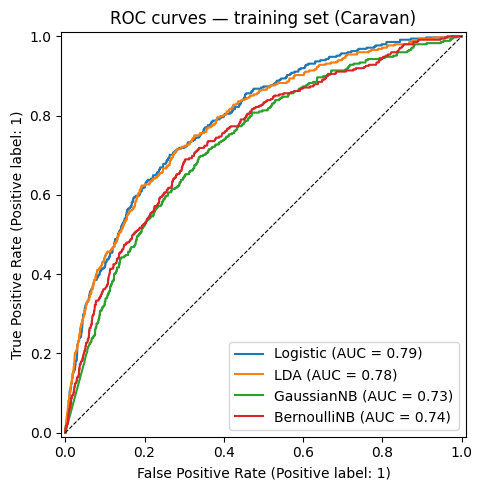

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))

for name, (clf, X_use) in classifiers.items():
    y_prob = clf.predict_proba(X_use)[:, 1]
    RocCurveDisplay.from_predictions(y, y_prob, name=name, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
ax.set_title('ROC curves — training set (Caravan)')
plt.tight_layout()
plt.show()

❓ **Question 4.3.** Based on the AUC values and ROC curves, which classifier performs best on the training set? Does the result match what you would have predicted from the correlation analysis in Part 3?

Logistic regression performs best (AUC = 0.79), followed closely by LDA (0.78), with the two Naive Bayes variants trailing (Bernoulli 0.74, Gaussian 0.73).

This matches what Part 3 suggested. The strong within-class correlations violate the conditional independence assumption that both Naive Bayes variants make, and neither can exploit the structure that LDA captures through its pooled covariance matrix. The near-equal AUC for logistic regression and LDA is consistent with the lecture: the two behave similarly when the boundary is roughly linear.

Note how little the accuracy column tells you. Gaussian Naive Bayes has the worst accuracy by a wide margin (0.19) and Logistic the best (0.94), but their AUCs differ by only 0.06. Accuracy here is mostly a report on where each model happens to put its default threshold relative to a 6% base rate.

### 4.4 Dataset Characteristics and Classifier Choice

The lecture noted that Naive Bayes is often competitive when predictors are high-dimensional and sparse. Part 0 measured both properties for this dataset.

❓ **Question 4.4.** Does the Caravan dataset fit that description? Use the EDA output from Part 0. If it does fit, why does Naive Bayes still come last here?

It fits on both counts. The dataset is high-dimensional (85 predictors against 5822 observations) and it is sparse: over half of all entries are zero, 37 of the 85 predictors are more than 80% zero, and only 18 are less than 10% zero. The sparse block is the product-ownership variables.

So the usual argument for Naive Bayes applies, and it still finishes last. The reason is the other half of Part 0 and all of Part 3. Sparsity is not the only thing that matters. The sociodemographic predictors are strongly correlated within class (MOSTYPE–MOSHOOFD, MGODPR–MGODGE), which is a direct violation of conditional independence, and LDA's pooled covariance exploits exactly the structure Naive Bayes throws away.

The sparsity argument for Naive Bayes is really an argument about $n$ relative to $p$: with few observations per parameter, a model that estimates $2p$ marginals is more stable than one estimating a $p \times p$ covariance matrix. Here $n / p \approx 68$, which is comfortable, so LDA can afford the full covariance matrix and the stability argument never gets to pay off.

***

## Part 5: Threshold Selection for the Best Classifier

Choose the classifier with the highest AUC from Part 4. We will now select an operating threshold that is more appropriate for this problem than the default 0.5.

### Exercise 5.1: Sensitivity and specificity against threshold

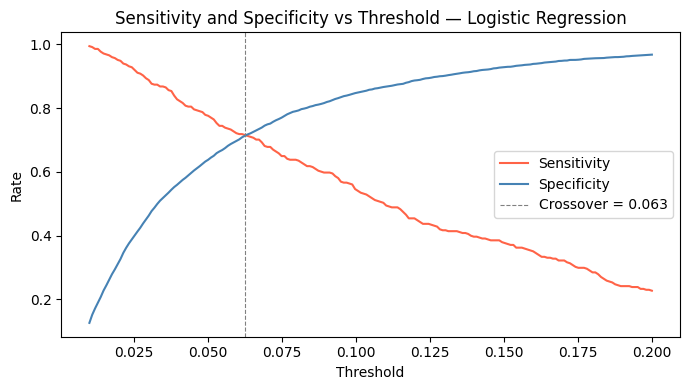

Crossover threshold: 0.063
Sensitivity at crossover: 0.7155
Specificity at crossover: 0.7132


In [23]:
### YOUR CODE HERE
# Using the best classifier from Part 4:
# 1. Plot sensitivity and specificity against threshold over the range [0.01, 0.20]
# 2. Mark the threshold where sensitivity = specificity
# 3. Choose and justify an operating threshold appropriate for the insurance context

thresholds = np.linspace(0.01, 0.20, 200)
sensitivities = []
specificities = []

y_prob_lr = clf_lr.predict_proba(X)[:, 1]

for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred_t).ravel()
    sensitivities.append(tp / (tp + fn))
    specificities.append(tn / (tn + fp))

sensitivities = np.array(sensitivities)
specificities = np.array(specificities)

# Threshold where sensitivity = specificity
crossover_idx = np.argmin(np.abs(sensitivities - specificities))
crossover_threshold = thresholds[crossover_idx]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, sensitivities, color='tomato', label='Sensitivity')
plt.plot(thresholds, specificities, color='steelblue', label='Specificity')
plt.axvline(crossover_threshold, color='gray', linestyle='--', linewidth=0.8,
            label=f'Crossover = {crossover_threshold:.3f}')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.title('Sensitivity and Specificity vs Threshold — Logistic Regression')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Crossover threshold: {crossover_threshold:.3f}")
print(f"Sensitivity at crossover: {sensitivities[crossover_idx]:.4f}")
print(f"Specificity at crossover: {specificities[crossover_idx]:.4f}")

❓ **Question 5.1a.** What threshold did you choose, and why? In the insurance context, what is the cost of a false negative (a likely buyer you fail to target) versus a false positive (a non-buyer you contact anyway)? How does this inform your threshold choice?

In direct marketing the two errors are not symmetric. A false negative costs the company a sale it could have made. A false positive costs one unit of contact, which for a mailshot or a call is small. The ratio is not 1:1, so the default threshold of 0.5, which implicitly assumes it is, is the wrong operating point.

The crossover threshold of about 0.06 gives sensitivity and specificity both near 0.72. That is a defensible default when the two error costs are treated as equal in importance. If a missed sale is judged more costly than a wasted contact, the threshold should go below the crossover, buying sensitivity at the expense of specificity.

Naming an exact threshold requires the two costs. If a policy earns the company $c_{\text{sale}}$ and a contact costs $c_{\text{contact}}$, it is worth contacting a customer whenever $P(\text{Yes} \mid X) > c_{\text{contact}} / c_{\text{sale}}$, which is the threshold. Without those two numbers the choice is a judgement, not a calculation, and it should be stated as one.

❓ **Question 5.1b.** All results in this lab are based on training-set evaluation. Why does this limit the conclusions you can draw about which classifier is best? What would you need to do to make a reliable comparison?

Training-set evaluation is optimistic. Every classifier has been evaluated on the same data it was trained on. A classifier that memorises the training data will score well here but fail on new customers. The AUC values and confusion matrices reflect in-sample fit, not generalisation. To make a reliable comparison you would need to estimate test error on held-out data, either by splitting into a train and test set or by using cross-validation. This is what we turn to in Week 7.

***

## Checklist

Before submitting, confirm:

- [ ] Part 1: Naive Bayes fitted; Exercises 1.4 and 1.5 completed; Questions 1.1-1.5 answered
- [ ] Part 2: LDA fitted; Exercises 2.1-2.3 completed; Questions 2.2 and 2.3 answered
- [ ] Part 3: Within-class correlations computed and interpreted; Question 3.1 answered
- [ ] Part 4: All four classifiers compared; ROC curves plotted; Questions 4.3 and 4.4 answered
- [ ] Part 5: Exercise 5.1 completed; Questions 5.1a and 5.1b answered